In [1]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

files = sorted(Path("Data").glob("*.csv"))

df = pd.concat(
    (pd.read_csv(
        f, 
        parse_dates=["started_at", "ended_at"], 
        dtype={"start_station_id": str, "end_station_id": str}
    ) for f in files),
    ignore_index=True,
)

df_raw_shape = df.shape
print(df_raw_shape)
df.head()

(5246236, 13)


,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,E4A8132DACF670C3,electric_bike,2026-08-10 14:31:22.100,2026-08-10 14:37:37.034,E 33 St & 5 Ave,6322.01,W 24 St & 7 Ave,6257.03,40.747659,-73.984907,40.744876,-73.995299,member
1,8382768C05C30BB4,electric_bike,2026-08-10 08:04:28.348,2026-08-10 08:33:27.680,Emerson Pl & Myrtle Ave,4683.02,W 24 St & 7 Ave,6257.03,40.693631,-73.962236,40.744876,-73.995299,member
2,3A1C43832BBE4FCD,classic_bike,2026-08-08 19:36:32.350,2026-08-08 19:43:47.890,Broadway & E 19 St,5980.11,W 24 St & 7 Ave,6257.03,40.738290,-73.990060,40.744876,-73.995299,member
3,5C9BC6DFC4DEA183,electric_bike,2026-08-05 14:34:27.749,2026-08-05 14:46:23.526,Sterling Pl & Bedford Ave,3993.03,Cumberland St & Lafayette Ave,4428.02,40.672695,-73.954131,40.687534,-73.972652,member
4,355579CC64D1BE20,electric_bike,2026-08-01 14:16:44.531,2026-08-01 14:29:39.539,Sterling Pl & Bedford Ave,3993.03,Cumberland St & Lafayette Ave,4428.02,40.672695,-73.954131,40.687534,-73.972652,member


# Warmup

## Cleaning

In [2]:
# Add a new column "ride_time" to the dataframe
df['ride_time'] = df['ended_at'] - df['started_at']

# Generate a boolean mask for each condition (too long, or negative)
long_ride_times = df["ride_time"] > pd.Timedelta(hours=3)
print("longer than 3 hours:", long_ride_times.sum())        # sum() counts all true values in the mask

negative_ride_times = df["ride_time"] < pd.Timedelta(0)
print("negative ride times:", negative_ride_times.sum())

missing_station = df["start_station_id"].isna() | df["end_station_id"].isna()
print("missing start/end station:", missing_station.sum())

df = df.loc[~(long_ride_times | negative_ride_times | missing_station)]
df_clean_shape = df.shape

print(f"before: {df_raw_shape}")
print(f"after: {df_clean_shape}")
print(f"dropped: {df_raw_shape[0] - df_clean_shape[0]} rows")

longer than 3 hours: 6020
negative ride times: 0
missing start/end station: 17156
before: (5246236, 13)
after: (5225284, 14)
dropped: 20952 rows


## 1) Histogram

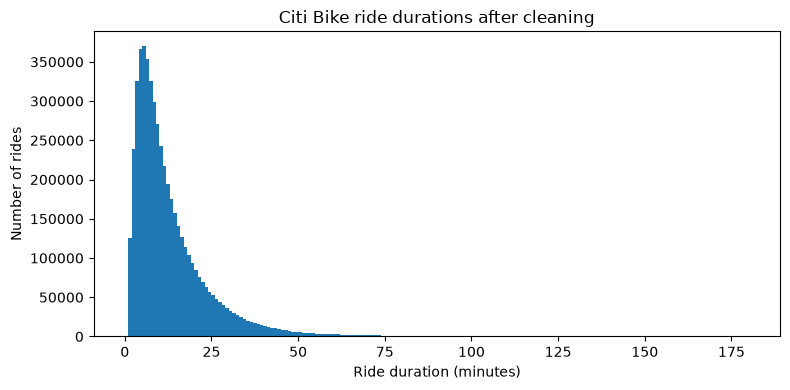

In [3]:
minutes = df["ride_time"].dt.total_seconds() / 60

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(minutes, bins=180, range=(0, 180))
ax.set_xlabel("Ride duration (minutes)")
ax.set_ylabel("Number of rides")
ax.set_title("Citi Bike ride durations after cleaning")
plt.tight_layout()
plt.show()

## 2) Expected time, and Variance

In [4]:
ride_times_in_minutes = df["ride_time"].dt.total_seconds() / 60

E_x = np.mean(ride_times_in_minutes)
Var_x = np.var(ride_times_in_minutes)
P_g20 = (ride_times_in_minutes > 20).sum() / df.shape[0]

print(f"E[X]: {E_x}")
print(f"Var[X]: {Var_x}")
print(f"P(X > 20): {P_g20}")

E[X]: 13.407342967224366
Var[X]: 157.21753576844358
P(X > 20): 0.18799016474511243


## 3) Conditional: P(X > 20 | Member)

In [5]:
# Citibike Members
citibike_member_rides = df["member_casual"] == "member"
P_member = citibike_member_rides.sum() / df.shape[0]

# Member, and ride longer than 20 minutes
citibike_member_and_g20_rides = (df["member_casual"] == "member") & ((df["ride_time"].dt.total_seconds() / 60) > 20)
P_g20_and_member = citibike_member_and_g20_rides.sum() / df.shape[0]

# P(X > 20 | Member)
P_g20_given_member = P_g20_and_member / P_member

print(f"P(X > 20 | Member): {P_g20_given_member}")

P(X > 20 | Member): 0.15331187684384096


## 4) P(member | X > 25)

In [6]:
p_joint = ((df["member_casual"] == "member") & ((df["ride_time"].dt.total_seconds() / 60) > 25)).sum()  # P(A and B)
p_ride_25_min = ((df["ride_time"].dt.total_seconds() / 60) > 25).sum()                                  # P(B)
print(f"P(member | ride > 25 min) = {p_joint / p_ride_25_min:.4f}")

P(member | ride > 25 min) = 0.6030


## 5) expected ride duration by bike type

In [7]:
electric_average_ride_time = df.loc[df["rideable_type"] == "electric_bike", "ride_time"].mean().total_seconds() / 60
classic_average_ride_time = df.loc[df["rideable_type"] == "classic_bike", "ride_time"].mean().total_seconds() / 60
print(f"Expected electric bike ride time: {electric_average_ride_time:.2f} min")
print(f"Expected classic bike ride time: {classic_average_ride_time:.2f} min")

Expected electric bike ride time: 13.36 min
Expected classic bike ride time: 13.54 min


## 6) P(bike type | X < 10)

In [8]:
short = df["ride_time"] < pd.Timedelta(minutes=10)
p_ride_less_than_10 = short.mean()                                # P(B)

p_joint = ((df["rideable_type"] == "electric_bike") & short).mean()   # P(A and B)
print(f"P(Electric Bike | Ride < 10) = {p_joint / p_ride_less_than_10:.2f}")

p_joint = ((df["rideable_type"] == "classic_bike") & short).mean()
print(f"P(Classic Bike | Ride < 10) = {p_joint / p_ride_less_than_10:.2f}")

p_electric = (df["rideable_type"] == "electric_bike").mean()
print(f"P(Electric Bike) overall = {p_electric:.2f}")

P(Electric Bike | Ride < 10) = 0.72
P(Classic Bike | Ride < 10) = 0.28
P(Electric Bike) overall = 0.73


# Part I: Modeling Citi Bike stations using Markov chains

## Station Selection

In [9]:
def block_flows(df, start_hr, end_hr):
    dep_mask = (df["started_at"].dt.dayofweek < 5) & df["started_at"].dt.hour.between(start_hr, end_hr-1)
    arr_mask = (df["ended_at"].dt.dayofweek < 5) & df["ended_at"].dt.hour.between(start_hr, end_hr-1)
    dep = df.loc[dep_mask].groupby("start_station_name").size()
    arr = df.loc[arr_mask].groupby("end_station_name").size()
    out = pd.DataFrame({"dep": dep, "arr": arr}).fillna(0)
    out["net"] = out["arr"] - out["dep"]
    out["total"] = out["arr"] + out["dep"]
    return out

am = block_flows(df, 7, 10)    # 7:00–9:59
pm = block_flows(df, 16, 19)   # 16:00–16:59

summary = am.add_suffix("_am").join(pm.add_suffix("_pm"), how="outer").fillna(0)
summary["total"] = summary["total_am"] + summary["total_pm"]
summary.sort_values("total", ascending=False).head(25)

,dep_am,arr_am,net_am,total_am,dep_pm,arr_pm,net_pm,total_pm,total
9 Ave & W 33 St,1798.0,4190.0,2392.0,5988.0,4571.0,2303.0,-2268.0,6874.0,12862.0
W 21 St & 6 Ave,2081.0,3085.0,1004.0,5166.0,3869.0,3039.0,-830.0,6908.0,12074.0
Park Ave & E 42 St,2184.0,3096.0,912.0,5280.0,3276.0,2537.0,-739.0,5813.0,11093.0
Pier 61 at Chelsea Piers,2417.0,1918.0,-499.0,4335.0,3149.0,3098.0,-51.0,6247.0,10582.0
W 31 St & 7 Ave,2043.0,2127.0,84.0,4170.0,3030.0,3122.0,92.0,6152.0,10322.0
E 17 St & Broadway,1543.0,2812.0,1269.0,4355.0,3253.0,2402.0,-851.0,5655.0,10010.0
Broadway & W 25 St,965.0,2566.0,1601.0,3531.0,3506.0,2148.0,-1358.0,5654.0,9185.0
6 Ave & W 33 St,1580.0,1596.0,16.0,3176.0,2704.0,3008.0,304.0,5712.0,8888.0
W 30 St & 10 Ave,1688.0,2307.0,619.0,3995.0,2540.0,2086.0,-454.0,4626.0,8621.0
1 Ave & E 68 St,1525.0,2690.0,1165.0,4215.0,3051.0,1339.0,-1712.0,4390.0,8605.0


In [10]:
# Claude code artifact for showing a physical map/location of top 25 bike stations! Artifact stored in stations_map.html


# import folium

# # One coordinate per station. Use the median, because e-bike GPS jitters
# coords = df.groupby("start_station_name")[["start_lat", "start_lng"]].median()

# top = (summary.sort_values("total", ascending=False)
#               .head(25)                     # big enough that some Brooklyn/Queens/Bronx stations show up
#               .join(coords, how="inner"))

# m = folium.Map(location=[40.74, -73.94], zoom_start=12, tiles="Esri.WorldGrayCanvas")

# for name, r in top.iterrows():
#     folium.CircleMarker(
#         location=[r["start_lat"], r["start_lng"]],
#         radius=3 + 12 * r["total"] / top["total"].max(),   # bigger = busier
#         color="red" if r["net_am"] > 0 else "blue",        # red = fills up in AM, blue = empties in AM
#         fill=True, fill_opacity=0.7,
#         tooltip=f"{name}<br>AM net {r['net_am']:+.0f} | PM net {r['net_pm']:+.0f}<br>total {r['total']:.0f}",
#     ).add_to(m)

# m.save("stations_map.html")   # send this file to your teammates
# m                              # displays inline in Jupyter

1. W 21 St & 6 Ave	  (Morning Surplus, Midtown)
2. 11 Ave & W 41 St     (Afternoon Surplus, Lower Midtown)
3. S 2 St & Kent Ave	   (Brooklyn, Roughly Equal in/out)